Planteamiento

En esta actividad se realizará una comparación climática entre Bogotá, Colombia, y Madrid, España, con el propósito de identificar semejanzas y diferencias en el comportamiento de la temperatura y la precipitación.

Hipótesis

Se plantea que Bogotá presenta temperaturas medias diarias más estables debido a su ubicación geográfica cercana al ecuador, mientras que Madrid experimenta mayores variaciones térmicas entre las estaciones,

En cuanto a las precipitaciones, se espera encontrar diferencias ya que Bogotá podría presentar una más lluvias, con respecto a la de Madrid debido a las diferencias de cada región.

Unidades

Tiempo 2016-2025
datos	- Diarios
Temperatura -C Centígrados 
Precipitación -	mm


In [1]:
#instalar librerías
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import hf_hub_download

from datetime import datetime
import csv

print("Todas las librerías se importaron correctamente")

/workspaces/analitica/.venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Todas las librerías se importaron correctamente


In [2]:
# Identificar el repositorio
repositorio = "tharinduperera/weather-clustering-data"

dataset = load_dataset(repositorio, split="train")

# Convertir a DataFrame
df = dataset.to_pandas()

print("Dataset cargado correctamente")
print("Dimensiones:", df.shape)


print("\nColumnas disponibles:")
print(df.columns.tolist())


display(df.head())

Generating train split: 762400 examples [00:05, 133450.99 examples/s] 


Dataset cargado correctamente
Dimensiones: (762400, 23)

Columnas disponibles:
['location_id', 'city', 'city_ascii', 'country', 'iso2', 'iso3', 'admin_name', 'capital', 'source_latitude', 'source_longitude', 'model_latitude', 'model_longitude', 'timezone', 'elevation', 'date', 'temperature_mean', 'temperature_max', 'temperature_min', 'precipitation_sum', 'relative_humidity_mean', 'wind_speed_mean', 'surface_pressure_mean', 'year']


,location_id,city,city_ascii,country,iso2,iso3,admin_name,capital,source_latitude,source_longitude,...,elevation,date,temperature_mean,temperature_max,temperature_min,precipitation_sum,relative_humidity_mean,wind_speed_mean,surface_pressure_mean,year
0,1004993580,Kabul,Kabul,Afghanistan,AF,AFG,Kābul,primary,34.5328,69.1658,...,1800.0,2016-01-01,4.2,9.9,-2.2,0.0,51,4.7,824.5,2016.0
1,1004993580,Kabul,Kabul,Afghanistan,AF,AFG,Kābul,primary,34.5328,69.1658,...,1800.0,2016-01-02,4.3,9.1,-0.7,0.0,69,4.2,825.3,2016.0
2,1004993580,Kabul,Kabul,Afghanistan,AF,AFG,Kābul,primary,34.5328,69.1658,...,1800.0,2016-01-03,4.1,6.3,0.5,4.1,89,3.5,823.2,2016.0
3,1004993580,Kabul,Kabul,Afghanistan,AF,AFG,Kābul,primary,34.5328,69.1658,...,1800.0,2016-01-04,4.2,6.7,1.2,7.1,96,3.8,822.2,2016.0
4,1004993580,Kabul,Kabul,Afghanistan,AF,AFG,Kābul,primary,34.5328,69.1658,...,1800.0,2016-01-05,1.5,7.2,-4.4,0.0,66,5.8,821.8,2016.0


In [3]:
# Crear la carpeta 
from pathlib import Path
carpeta_datos = Path("datos")
carpeta_datos.mkdir(parents=True, exist_ok=True)

# Convertir la fecha
df["date"] = pd.to_datetime(df["date"])

# Filtrar únicamente Bogotá y Madrid
bogota = df[
    (df["city_ascii"] == "Bogota") &
    (df["iso2"] == "CO")
].copy()

madrid = df[
    (df["city_ascii"] == "Madrid") &
    (df["iso2"] == "ES")
].copy()

# Eliminar registros completamente duplicados
bogota = bogota.drop_duplicates()
madrid = madrid.drop_duplicates()

# Guardar los archivos CSV
bogota.to_csv(carpeta_datos / "Bogota.csv", index=False)
madrid.to_csv(carpeta_datos / "Madrid.csv", index=False)

print("Archivos CSV guardados correctamente")
print("Bogotá:", len(bogota), "registros")
print("Madrid:", len(madrid), "registros")

Archivos CSV guardados correctamente
Bogotá: 7624 registros
Madrid: 7624 registros


In [4]:
# Leer los archivos desde la carpeta datos
bogota = pd.read_csv("datos/Bogota.csv", parse_dates=["date"])
madrid = pd.read_csv("datos/Madrid.csv", parse_dates=["date"])

print("Archivos cargados correctamente")

print("\nDatos de Bogotá:")
display(bogota.head())

print("\nDatos de Madrid:")
display(madrid.head())

Archivos cargados correctamente

Datos de Bogotá:


,location_id,city,city_ascii,country,iso2,iso3,admin_name,capital,source_latitude,source_longitude,...,elevation,date,temperature_mean,temperature_max,temperature_min,precipitation_sum,relative_humidity_mean,wind_speed_mean,surface_pressure_mean,year
0,1170483426,Bogotá,Bogota,Colombia,CO,COL,Bogotá,primary,4.6097,-74.0817,...,2582.0,2016-01-01,14.7,19.4,10.1,1.5,78,6.6,754.8,2016.0
1,1170483426,Bogotá,Bogota,Colombia,CO,COL,Bogotá,primary,4.6097,-74.0817,...,2582.0,2016-01-02,13.4,17.2,10.1,4.0,87,5.5,754.6,2016.0
2,1170483426,Bogotá,Bogota,Colombia,CO,COL,Bogotá,primary,4.6097,-74.0817,...,2582.0,2016-01-03,13.9,18.7,9.3,4.4,85,5.0,754.6,2016.0
3,1170483426,Bogotá,Bogota,Colombia,CO,COL,Bogotá,primary,4.6097,-74.0817,...,2582.0,2016-01-04,14.3,18.8,11.3,4.0,85,3.3,755.1,2016.0
4,1170483426,Bogotá,Bogota,Colombia,CO,COL,Bogotá,primary,4.6097,-74.0817,...,2582.0,2016-01-05,15.4,20.5,10.6,6.1,81,1.9,756.1,2016.0



Datos de Madrid:


,location_id,city,city_ascii,country,iso2,iso3,admin_name,capital,source_latitude,source_longitude,...,elevation,date,temperature_mean,temperature_max,temperature_min,precipitation_sum,relative_humidity_mean,wind_speed_mean,surface_pressure_mean,year
0,1724616994,Madrid,Madrid,Spain,ES,ESP,Madrid,primary,40.4169,-3.7033,...,660.0,2016-01-01,9.6,13.2,6.4,1.4,92,10.3,943.8,2016.0
1,1724616994,Madrid,Madrid,Spain,ES,ESP,Madrid,primary,40.4169,-3.7033,...,660.0,2016-01-02,9.1,12.1,6.0,1.1,76,10.3,943.5,2016.0
2,1724616994,Madrid,Madrid,Spain,ES,ESP,Madrid,primary,40.4169,-3.7033,...,660.0,2016-01-03,6.8,10.8,3.4,0.0,92,12.2,939.4,2016.0
3,1724616994,Madrid,Madrid,Spain,ES,ESP,Madrid,primary,40.4169,-3.7033,...,660.0,2016-01-04,11.9,13.0,8.8,8.9,92,20.7,929.0,2016.0
4,1724616994,Madrid,Madrid,Spain,ES,ESP,Madrid,primary,40.4169,-3.7033,...,660.0,2016-01-05,6.9,8.9,4.2,0.4,70,10.2,930.7,2016.0


In [5]:
# Buscar Bogotá y Madrid 

ciudades_busqueda = df[
    df["city_ascii"].str.contains(
        "Bogota|Madrid",
        case=False,
        na=False
    )
][["city", "city_ascii", "country", "iso2"]].drop_duplicates()

display(ciudades_busqueda)

,city,city_ascii,country,iso2
7362,Bogotá,Bogota,Colombia,CO
22226,Madrid,Madrid,Spain,ES


In [6]:
# Consultar las ciudades y países disponibles

ciudades = df[["city", "country"]].drop_duplicates()

print("Ciudades disponibles:")
display(
    ciudades[
        ciudades["city"].str.contains(
            "Bogota|Madrid",
            case=False,
            na=False
        )
    ]
)

Ciudades disponibles:


,city,country
22226,Madrid,Spain


In [7]:
#Tiempo de los datos

# Convertir la columna de fechas
df["date"] = pd.to_datetime(df["date"])

# Filtrar los registros de cada ciudad
bogota = df[df["iso2"] == "CO"].copy()
madrid = df[df["iso2"] == "ES"].copy()

for nombre, datos in [("Bogotá", bogota), ("Madrid", madrid)]:
    print(f"\n--- {nombre} ---")
    print("Cantidad de registros:", len(datos))
    print("Fecha inicial:", datos["date"].min())
    print("Fecha final:", datos["date"].max())
    print("Años disponibles:", sorted(datos["date"].dt.year.unique()))


--- Bogotá ---
Cantidad de registros: 7624
Fecha inicial: 2016-01-01 00:00:00
Fecha final: 2026-11-14 00:00:00
Años disponibles: [np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

--- Madrid ---
Cantidad de registros: 15248
Fecha inicial: 2016-01-01 00:00:00
Fecha final: 2026-11-14 00:00:00
Años disponibles: [np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


In [8]:
#comprobar los años disponibles
anios_bogota = set(bogota["date"].dt.year.unique())
anios_madrid = set(madrid["date"].dt.year.unique())

anios_comunes = sorted(anios_bogota.intersection(anios_madrid))

print("Años disponibles en ambas ciudades:", anios_comunes)

Años disponibles en ambas ciudades: [np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


In [9]:
# Contar registros por año y ciudad

bogota["año"] = bogota["date"].dt.year
madrid["año"] = madrid["date"].dt.year

print("REGISTROS POR AÑO - BOGOTÁ")
display(bogota.groupby("año")["date"].count())

print("REGISTROS POR AÑO - MADRID")
display(madrid.groupby("año")["date"].count())

REGISTROS POR AÑO - BOGOTÁ


año
2016    732
2017    730
2018    730
2019    730
2020    732
2021    730
2022    730
2023    730
2024    732
2025    730
2026    318
Name: date, dtype: int64

REGISTROS POR AÑO - MADRID


año
2016    1464
2017    1460
2018    1460
2019    1460
2020    1464
2021    1460
2022    1460
2023    1460
2024    1464
2025    1460
2026     636
Name: date, dtype: int64

In [10]:
# Filtrar
bogota = df[df["city_ascii"] == "Bogota"].copy()
madrid = df[df["city_ascii"] == "Madrid"].copy()

# registros por año
for nombre, datos in [("Bogotá", bogota), ("Madrid", madrid)]:
    print(f"\n--- {nombre} ---")
    print("Total de registros:", len(datos))
    print(datos.groupby(datos["date"].dt.year)["date"].count())

    print("Fechas duplicadas:", datos["date"].duplicated().sum())


--- Bogotá ---
Total de registros: 7624
date
2016    732
2017    730
2018    730
2019    730
2020    732
2021    730
2022    730
2023    730
2024    732
2025    730
2026    318
Name: date, dtype: int64
Fechas duplicadas: 3653

--- Madrid ---
Total de registros: 7624
date
2016    732
2017    730
2018    730
2019    730
2020    732
2021    730
2022    730
2023    730
2024    732
2025    730
2026    318
Name: date, dtype: int64
Fechas duplicadas: 3653


In [11]:
# Revisión

for nombre, datos in [("Bogotá", bogota), ("Madrid", madrid)]:
    print(f"\n--- {nombre} ---")

    display(
        datos.groupby(
            ["location_id", "city", "country", "admin_name",
             "source_latitude", "source_longitude"]
        )
        .agg(
            registros=("date", "count"),
            fecha_inicial=("date", "min"),
            fecha_final=("date", "max")
        )
        .reset_index()
    )


--- Bogotá ---


,location_id,city,country,admin_name,source_latitude,source_longitude,registros,fecha_inicial,fecha_final
0,1170483426,Bogotá,Colombia,Bogotá,4.6097,-74.0817,7624,2016-01-01,2026-11-14



--- Madrid ---


,location_id,city,country,admin_name,source_latitude,source_longitude,registros,fecha_inicial,fecha_final
0,1724616994,Madrid,Spain,Madrid,40.4169,-3.7033,7624,2016-01-01,2026-11-14


In [12]:
## Examinando las fechas

columnas = [
    "date",
    "temperature_mean",
    "temperature_max",
    "temperature_min",
    "precipitation_sum",
    "relative_humidity_mean",
    "wind_speed_mean",
    "surface_pressure_mean"
]

print("BOGOTÁ: primeros registros de una fecha")
display(
    bogota[bogota["date"] == "2016-01-01"][columnas]
)

print("MADRID: primeros registros de una fecha")
display(
    madrid[madrid["date"] == "2016-01-01"][columnas]
)

print("\nFilas completamente duplicadas:")
print("Bogotá:", bogota.duplicated().sum())
print("Madrid:", madrid.duplicated().sum())

BOGOTÁ: primeros registros de una fecha


,date,temperature_mean,temperature_max,temperature_min,precipitation_sum,relative_humidity_mean,wind_speed_mean,surface_pressure_mean
7362,2016-01-01,14.7,19.4,10.1,1.5,78,6.6,754.8
372662,2016-01-01,14.7,19.4,10.1,1.5,78,6.6,754.8


MADRID: primeros registros de una fecha


,date,temperature_mean,temperature_max,temperature_min,precipitation_sum,relative_humidity_mean,wind_speed_mean,surface_pressure_mean
22226,2016-01-01,9.6,13.2,6.4,1.4,92,10.3,943.8
387526,2016-01-01,9.6,13.2,6.4,1.4,92,10.3,943.8



Filas completamente duplicadas:
Bogotá: 0
Madrid: 0


In [13]:
variables = [
    "temperature_mean",
    "temperature_max",
    "temperature_min",
    "precipitation_sum"
]

In [14]:
# Conservar una fila por fecha
bogota = bogota.sort_values("date").drop_duplicates(
    subset=["date"], keep="first"
).copy()

madrid = madrid.sort_values("date").drop_duplicates(
    subset=["date"], keep="first"
).copy()

# Seleccionar los mismos años completos
fecha_inicio = "2016-01-01"
fecha_fin = "2025-12-31"

bogota = bogota[
    bogota["date"].between(fecha_inicio, fecha_fin)
].copy()

madrid = madrid[
    madrid["date"].between(fecha_inicio, fecha_fin)
].copy()

# Comprobar los resultados
for nombre, datos in [("Bogotá", bogota), ("Madrid", madrid)]:
    print(f"\n--- {nombre} ---")
    print("Registros:", len(datos))
    print("Fecha inicial:", datos["date"].min())
    print("Fecha final:", datos["date"].max())
    print("Fechas únicas:", datos["date"].nunique())
    print("Fechas duplicadas:", datos["date"].duplicated().sum())
    print("Valores faltantes:")
    display(datos[variables].isna().sum())


--- Bogotá ---
Registros: 3653
Fecha inicial: 2016-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Fechas únicas: 3653
Fechas duplicadas: 0
Valores faltantes:


temperature_mean     0
temperature_max      0
temperature_min      0
precipitation_sum    0
dtype: int64


--- Madrid ---
Registros: 3653
Fecha inicial: 2016-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Fechas únicas: 3653
Fechas duplicadas: 0
Valores faltantes:


temperature_mean     0
temperature_max      0
temperature_min      0
precipitation_sum    0
dtype: int64

In [15]:
#Arreglos numpy

temp_bogota = bogota["temperature_mean"].to_numpy(dtype=float)
temp_max_bogota = bogota["temperature_max"].to_numpy(dtype=float)
temp_min_bogota = bogota["temperature_min"].to_numpy(dtype=float)
prec_bogota = bogota["precipitation_sum"].to_numpy(dtype=float)

temp_madrid = madrid["temperature_mean"].to_numpy(dtype=float)
temp_max_madrid = madrid["temperature_max"].to_numpy(dtype=float)
temp_min_madrid = madrid["temperature_min"].to_numpy(dtype=float)
prec_madrid = madrid["precipitation_sum"].to_numpy(dtype=float)

print("Arreglos NumPy creados correctamente")

print("\nDimensiones:")
print("Temperatura Bogotá:", temp_bogota.shape)
print("Precipitación Bogotá:", prec_bogota.shape)
print("Temperatura Madrid:", temp_madrid.shape)
print("Precipitación Madrid:", prec_madrid.shape)


Arreglos NumPy creados correctamente

Dimensiones:
Temperatura Bogotá: (3653,)
Precipitación Bogotá: (3653,)
Temperatura Madrid: (3653,)
Precipitación Madrid: (3653,)


In [17]:
#verificacion de fechas

fechas_bogota = bogota["date"].to_numpy()
fechas_madrid = madrid["date"].to_numpy()

print(
    "¿Las fechas coinciden en ambas ciudades?",
    np.array_equal(fechas_bogota, fechas_madrid)
)

¿Las fechas coinciden en ambas ciudades? True


In [18]:
#creando mascaras

# días lluviosos
lluvia_bogota = prec_bogota > 0
lluvia_madrid = prec_madrid > 0

#temperatura media superior a 20 °C
calor_bogota = temp_bogota > 20
calor_madrid = temp_madrid > 20

print("DÍAS LLUVIOSOS")
print("Bogotá:", np.sum(lluvia_bogota))
print("Madrid:", np.sum(lluvia_madrid))

print("\nDÍAS CON TEMPERATURA MEDIA SUPERIOR A 20 °C")
print("Bogotá:", np.sum(calor_bogota))
print("Madrid:", np.sum(calor_madrid))

DÍAS LLUVIOSOS
Bogotá: 3164
Madrid: 1195

DÍAS CON TEMPERATURA MEDIA SUPERIOR A 20 °C
Bogotá: 0
Madrid: 1134


In [26]:
#Creando estadísticas

def calcular_estadisticas(nombre, temperatura, temp_max, temp_min,
                          precipitacion, dias_lluviosos):

    print(f"\n--- {nombre} ---")

    print(f"Temperatura media: {np.mean(temperatura):.2f} °C")
    print(f"Temperatura máxima registrada: {np.max(temp_max):.2f} °C")
    print(f"Temperatura mínima registrada: {np.min(temp_min):.2f} °C")

    print(f"Precipitación acumulada: {np.sum(precipitacion):.2f} mm")
    print(f"Días lluviosos: {np.sum(dias_lluviosos)}")

    print(f"Desviación estándar de temperatura media: "
          f"{np.std(temperatura):.2f} °C")


calcular_estadisticas(
    "BOGOTÁ",
    temp_bogota,
    temp_max_bogota,
    temp_min_bogota,
    prec_bogota,
    lluvia_bogota
)

calcular_estadisticas(
    "MADRID",
    temp_madrid,
    temp_max_madrid,
    temp_min_madrid,
    prec_madrid,
    lluvia_madrid
)



--- BOGOTÁ ---
Temperatura media: 14.05 °C
Temperatura máxima registrada: 22.70 °C
Temperatura mínima registrada: 4.40 °C
Precipitación acumulada: 12041.60 mm
Días lluviosos: 3164
Desviación estándar de temperatura media: 0.76 °C

--- MADRID ---
Temperatura media: 15.50 °C
Temperatura máxima registrada: 41.10 °C
Temperatura mínima registrada: -8.60 °C
Precipitación acumulada: 4484.60 mm
Días lluviosos: 1195
Desviación estándar de temperatura media: 7.90 °C


In [27]:
# gráficas comparativas

# Crear columnas
bogota["año"] = bogota["date"].dt.year
bogota["mes"] = bogota["date"].dt.month

madrid["año"] = madrid["date"].dt.year
madrid["mes"] = madrid["date"].dt.month

#meses
nombres_meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

# Temperatura promedio 
temp_mensual_bogota = (
    bogota.groupby(["año", "mes"])["temperature_mean"].mean()
    .groupby("mes").mean()
)

temp_mensual_madrid = (
    madrid.groupby(["año", "mes"])["temperature_mean"].mean()
    .groupby("mes").mean()
)

# Precipitación acumulada
prec_mensual_bogota = (
    bogota.groupby(["año", "mes"])["precipitation_sum"].sum()
    .groupby("mes").mean()
)

prec_mensual_madrid = (
    madrid.groupby(["año", "mes"])["precipitation_sum"].sum()
    .groupby("mes").mean()
)

print("Datos mensuales calculados correctamente")

Datos mensuales calculados correctamente


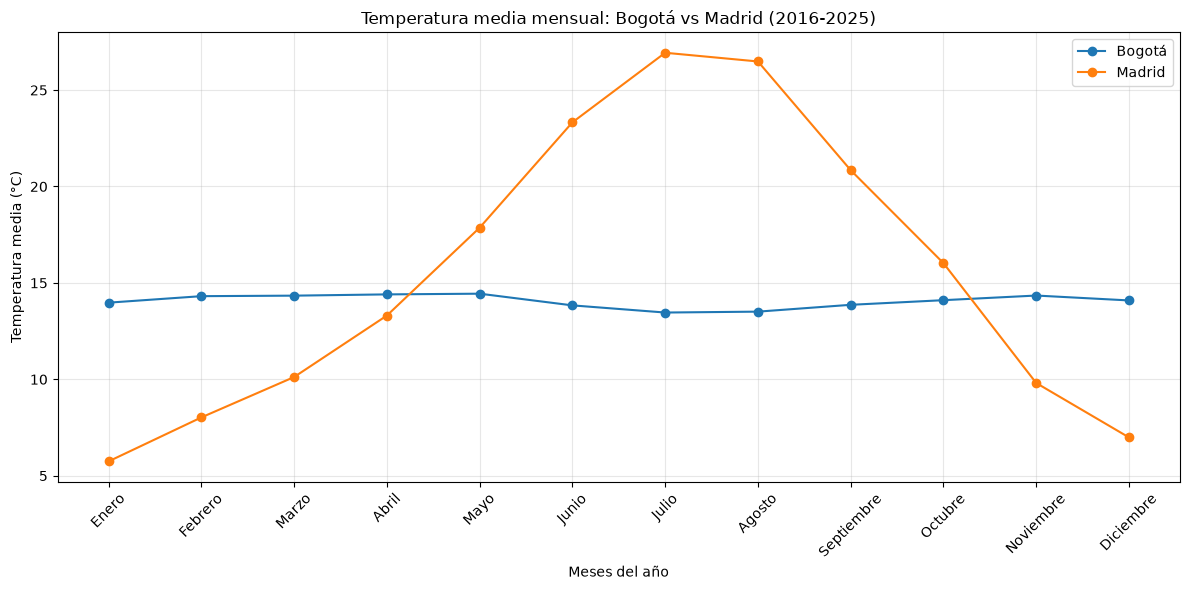

In [21]:
# Crear gráfica
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, 13),
    temp_mensual_bogota.values,
    marker="o",
    label="Bogotá"
)

plt.plot(
    range(1, 13),
    temp_mensual_madrid.values,
    marker="o",
    label="Madrid"
)

plt.title("Temperatura media mensual: Bogotá vs Madrid (2016-2025)")
plt.xlabel("Meses del año")
plt.ylabel("Temperatura media (°C)")

plt.xticks(range(1, 13), nombres_meses, rotation=45)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

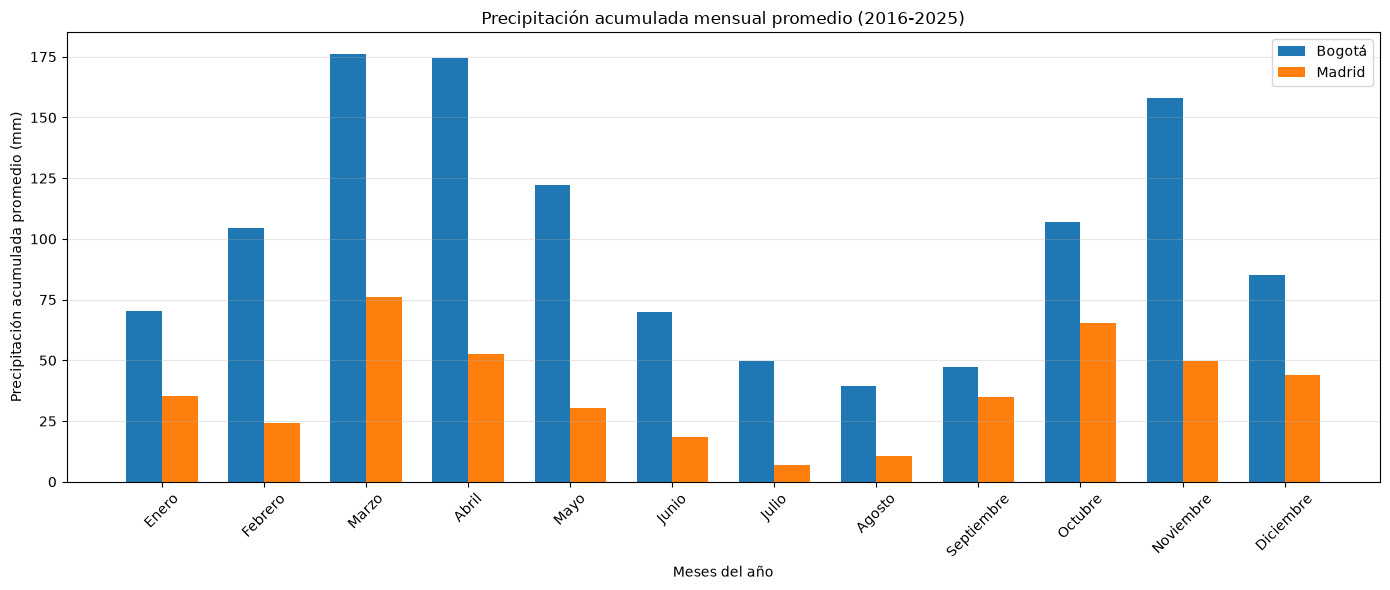

In [22]:
#grafica temperatura mensual

x = np.arange(12)
ancho = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - ancho/2,
    prec_mensual_bogota.values,
    width=ancho,
    label="Bogotá"
)

plt.bar(
    x + ancho/2,
    prec_mensual_madrid.values,
    width=ancho,
    label="Madrid"
)

plt.title("Precipitación acumulada mensual promedio (2016-2025)")
plt.xlabel("Meses del año")
plt.ylabel("Precipitación acumulada promedio (mm)")

plt.xticks(x, nombres_meses, rotation=45)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

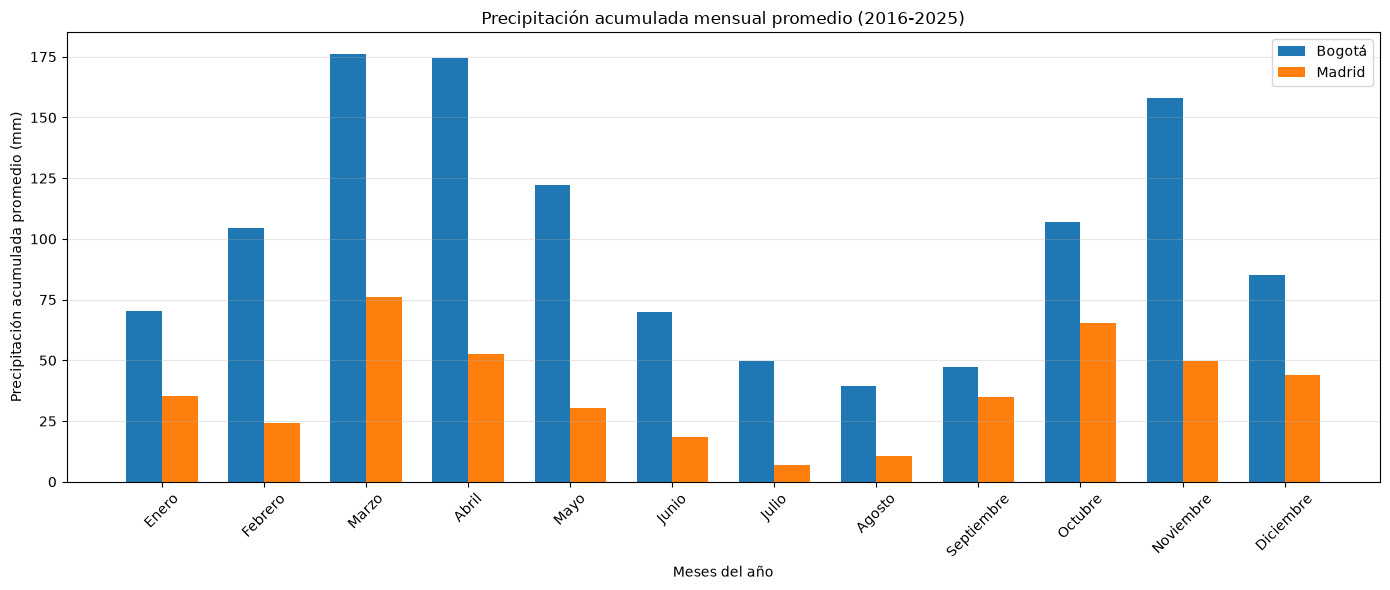

In [23]:
#gráfica presipitación mensual

# Configurar posiciones de las barras
x = np.arange(12)
ancho = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - ancho/2,
    prec_mensual_bogota.values,
    width=ancho,
    label="Bogotá"
)

plt.bar(
    x + ancho/2,
    prec_mensual_madrid.values,
    width=ancho,
    label="Madrid"
)

plt.title("Precipitación acumulada mensual promedio (2016-2025)")
plt.xlabel("Meses del año")
plt.ylabel("Precipitación acumulada promedio (mm)")

plt.xticks(x, nombres_meses, rotation=45)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

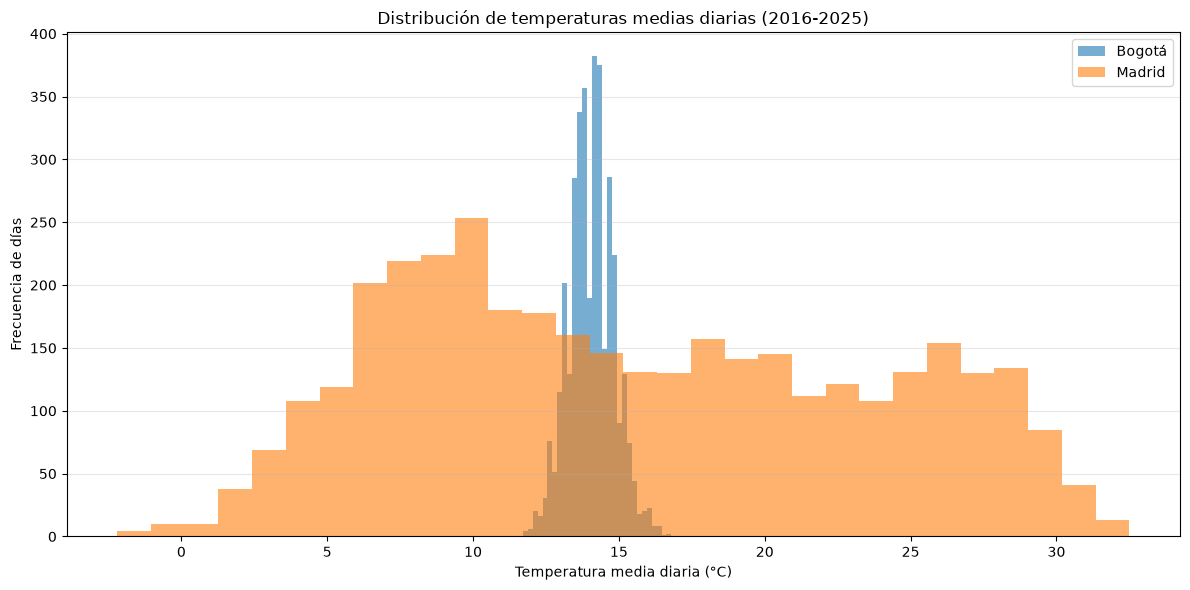

In [24]:
#grafica temperatura

plt.figure(figsize=(12, 6))

plt.hist(
    temp_bogota,
    bins=30,
    alpha=0.6,
    label="Bogotá"
)

plt.hist(
    temp_madrid,
    bins=30,
    alpha=0.6,
    label="Madrid"
)

plt.title("Distribución de temperaturas medias diarias (2016-2025)")
plt.xlabel("Temperatura media diaria (°C)")
plt.ylabel("Frecuencia de días")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
#comparación de resultados
resumen_mensual = pd.DataFrame({
    "Mes": nombres_meses,
    "Temperatura Bogotá (°C)": temp_mensual_bogota.values,
    "Temperatura Madrid (°C)": temp_mensual_madrid.values,
    "Precipitación Bogotá (mm)": prec_mensual_bogota.values,
    "Precipitación Madrid (mm)": prec_mensual_madrid.values
})

display(resumen_mensual.round(2))

print("TEMPERATURA")

print(
    "Bogotá - Mes más cálido:",
    nombres_meses[temp_mensual_bogota.values.argmax()]
)

print(
    "Madrid - Mes más cálido:",
    nombres_meses[temp_mensual_madrid.values.argmax()]
)

print("\nPRECIPITACIÓN")

print(
    "Bogotá - Mes más lluvioso:",
    nombres_meses[prec_mensual_bogota.values.argmax()]
)

print(
    "Madrid - Mes más lluvioso:",
    nombres_meses[prec_mensual_madrid.values.argmax()]
)

,Mes,Temperatura Bogotá (°C),Temperatura Madrid (°C),Precipitación Bogotá (mm),Precipitación Madrid (mm)
0,Enero,13.98,5.75,70.27,35.51
1,Febrero,14.31,8.03,104.49,24.40
2,Marzo,14.34,10.12,176.24,76.01
3,Abril,14.40,13.31,174.62,52.60
4,Mayo,14.44,17.86,122.00,30.57
5,Junio,13.83,23.33,69.95,18.36
6,Julio,13.46,26.93,49.66,7.05
7,Agosto,13.51,26.48,39.37,10.42
8,Septiembre,13.86,20.84,47.13,34.71
9,Octubre,14.10,16.02,107.10,65.29


TEMPERATURA
Bogotá - Mes más cálido: Mayo
Madrid - Mes más cálido: Julio

PRECIPITACIÓN
Bogotá - Mes más lluvioso: Marzo
Madrid - Mes más lluvioso: Marzo


Resultados 

Para la comparación se utilizó un periodo comprendido entre 2016 y 2025 ya que ambas ciudades contaban con los registros disponibles en huggingface.

se contó con 3653 observaciones diarias por ciudad lo que permitieron también observaciones diarias.

-Una diferencia es la variación de de las temperaturas entre las dos ciudades, tiene gran importancia las estaciones en Madrid a diferencia de Bogotá

-Bogotá tiene una temperatura media de 14,05 C mientras que Madrid 15,50 C, los resultados demuetran que las temperaturas a diario son más estables en Bogotá.

-Otra diferencia en las precipitaciones de Madrid se registra una un acumulado de 4.484 mm con 1195 días lluviosos mientras que Bogotá 12.041mm de presipitación acumulada y 3164 días lluviosos

-Las gráficas comparativas complementan los resultados se observa ladistribucioón mensual de la temperatura y presipitaciones.

En cuanto a la hipótesis se puede concluir que se cumple debido a las condiciones geográficas de cada ciudad, Bogotá con temperatuas medias y lluvias , y Madrid presenta mayor variación en temperatura y lluvia.